In [ ]:
https://github.com/01039959/Statistical-Techniques-for-Data-Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from scipy import stats
from scipy.stats import binom, poisson, norm

In [4]:
df = pd.read_csv("2024-04-29-excel-total-tree-population.csv")

In [6]:
display(df.head(10))

,ID,Age,Condition,Proximity,BuildingNumber,Street,Area,StemDiameter,Spread,Height,Species
0,07PH,NaN,NaN,NaN,6 8,ABBEY DRIVE,NaN,NaN,NaN,NaN,Suitable Planting Location
1,07PJ,Middle Aged (Within second third of lifespan),Fair (Reduced Vitality/Some Defects),NaN,14 16,ABBEY DRIVE,NaN,NaN,NaN,NaN,Suitable Planting Location
2,07R5,NaN,NaN,NaN,37 39,ABBEY DRIVE,NaN,NaN,NaN,NaN,Suitable Planting Location
3,07R7,NaN,NaN,NaN,47 49,ABBEY DRIVE,NaN,NaN,NaN,NaN,Suitable Planting Location
4,07RA,NaN,NaN,OPPOSITE,28,ABBEY DRIVE,NaN,NaN,NaN,NaN,Suitable Planting Location
5,07S8,NaN,NaN,OPPOSITE,32,ABBEY DRIVE,NaN,NaN,NaN,NaN,Suitable Planting Location
6,07SB,NaN,NaN,OPPOSITE,36,ABBEY DRIVE,NaN,NaN,NaN,NaN,Suitable Planting Location
7,07SG,NaN,NaN,OPPOSITE,44 46,ABBEY DRIVE,NaN,NaN,NaN,NaN,NaN
8,07SH,NaN,NaN,OPPOSITE,42 44,ABBEY DRIVE,NaN,NaN,NaN,NaN,NaN
9,07SN,NaN,NaN,OPPOSITE,56 58,ABBEY DRIVE,NaN,NaN,NaN,NaN,Suitable Planting Location


In [7]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 15962
Number of columns: 11


In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15962 entries, 0 to 15961
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   ID              15962 non-null  object
 1   Age             15016 non-null  object
 2   Condition       15015 non-null  object
 3   Proximity       8555 non-null   object
 4   BuildingNumber  10929 non-null  object
 5   Street          14721 non-null  object
 6   Area            1946 non-null   object
 7   StemDiameter    14941 non-null  object
 8   Spread          15005 non-null  object
 9   Height          14933 non-null  object
 10  Species         15810 non-null  object
dtypes: object(11)
memory usage: 1.3+ MB
None


In [11]:
#Missing Values in each column

In [10]:
missing = df.isnull().sum()
missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage (%)": (missing / len(df) * 100).round(2)
})
display(missing_summary.sort_values(
    "Missing Percentage (%)",
    ascending=False
))

,Missing Values,Missing Percentage (%)
Area,14016,87.81
Proximity,7407,46.40
BuildingNumber,5033,31.53
Street,1241,7.77
Height,1029,6.45
StemDiameter,1021,6.40
Spread,957,6.00
Age,946,5.93
Condition,947,5.93
Species,152,0.95


In [12]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 16


In [13]:
print("Unique IDs:", df["ID"].nunique())
print("Total records:", len(df))

Unique IDs: 15824
Total records: 15962


In [14]:
#Descriptive Statiltics

In [15]:
display(df.describe())

,ID,Age,Condition,Proximity,BuildingNumber,Street,Area,StemDiameter,Spread,Height,Species
count,15962,15016,15015,8555,10929,14721,1946,14941,15005,14933,15810
unique,15824,6,9,19,2851,634,8,31,6,6,518
top,0.00E+00,Middle Aged (Within second third of lifespan),Fair (Reduced Vitality/Some Defects),FRONT OF,1,GRIFFITH AVENUE,St Annes Park - North Central East Parks District,26cm-30cm (@1.5m),6-9m (Diameter),05 to 10m,Platanus x hispanica
freq,110,5711,11887,4442,177,1003,849,1621,4456,4954,2350


In [16]:
age_summary = pd.DataFrame({
    "Frequency": df["Age"].value_counts(dropna=False),
    "Percentage (%)": (
        df["Age"].value_counts(dropna=False, normalize=True) * 100
    ).round(2)
})
display(age_summary)

,Frequency,Percentage (%)
Age,,
Middle Aged (Within second third of lifespan),5711,35.78
Mature (Within final third of lifespan),4362,27.33
Young (Within first third of life span),4176,26.16
NaN,946,5.93
Newly Planted (Within 5 years),617,3.87
Over Mature (In natural decline),120,0.75
Ancient (Ruin),30,0.19


In [17]:
condition_summary = pd.DataFrame({
    "Frequency": df["Condition"].value_counts(dropna=False),
    "Percentage (%)": (
        df["Condition"].value_counts(dropna=False, normalize=True) * 100
    ).round(2)
})
display(condition_summary)

,Frequency,Percentage (%)
Condition,,
Fair (Reduced Vitality/Some Defects),11887,74.47
Good (Normal Vitality. No Major Defects),1688,10.58
Poor (Low Vitality/Extensive Defects),1122,7.03
NaN,947,5.93
Dead,185,1.16
Monolith,51,0.32
Felled,27,0.17
Fallen,21,0.13
Stump,17,0.11


In [18]:
display(df["Species"].value_counts().head(10))

Species
Platanus x hispanica           2350
Acer pseudoplatanus            1853
Acer platanoides               1328
Tilia x europaea               1145
Tilia cordata                  1098
Quercus ilex                    547
Carpinus betulus Fastigiata     540
Aesculus hippocastanum          395
Fraxinus excelsior              348
Corylus colurna                 342
Name: count, dtype: int64

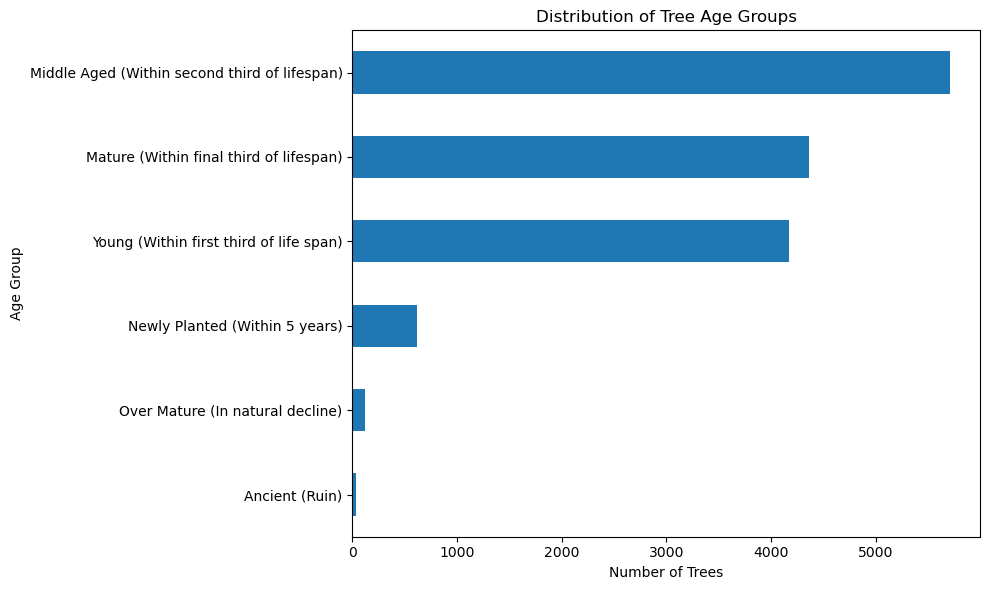

In [19]:
#Graph 1: Distribution of Tree Age Groups
age_counts = df["Age"].value_counts().sort_values()
plt.figure(figsize=(10, 6))
age_counts.plot(kind="barh")
plt.title("Distribution of Tree Age Groups")
plt.xlabel("Number of Trees")
plt.ylabel("Age Group")
plt.tight_layout()
plt.show()

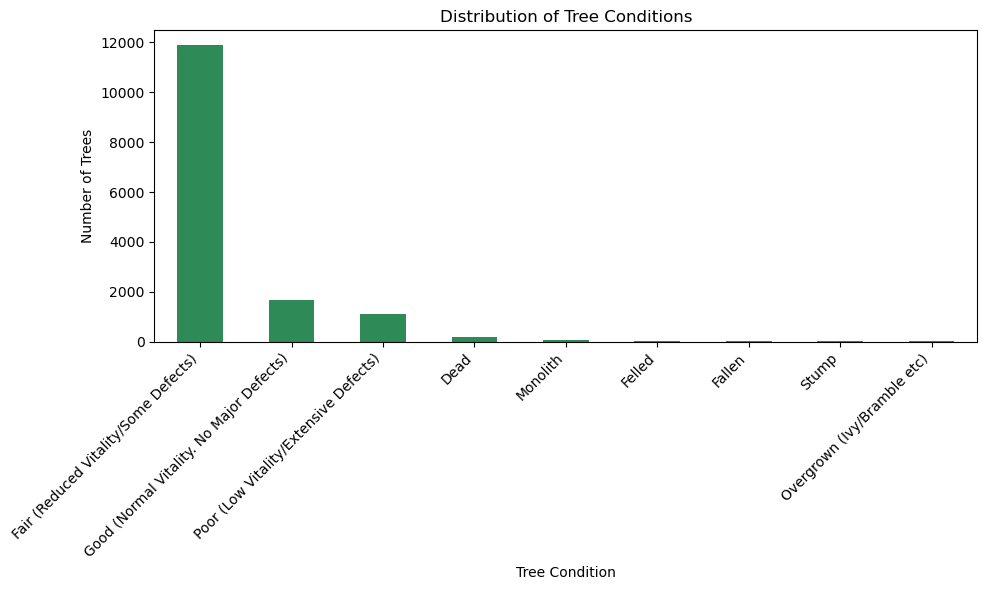

In [20]:
#Graph 2: Distribution of Tree Conditions
condition_counts = df["Condition"].value_counts()
plt.figure(figsize=(10, 6))
condition_counts.plot(kind="bar", color="seagreen")
plt.title("Distribution of Tree Conditions")
plt.xlabel("Tree Condition")
plt.ylabel("Number of Trees")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

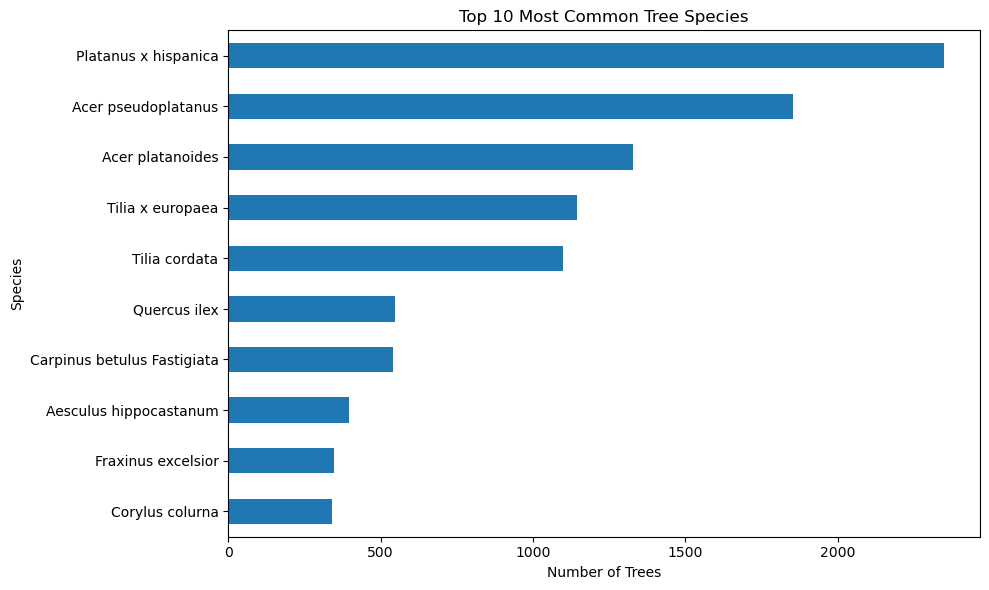

In [21]:
#Graph 3: Top 10 Most Common Tree Species
top_species = df["Species"].value_counts().head(10)
plt.figure(figsize=(10, 6))
top_species.sort_values().plot(kind="barh")
plt.title("Top 10 Most Common Tree Species")
plt.xlabel("Number of Trees")
plt.ylabel("Species")
plt.tight_layout()
plt.show()

In [50]:
import pandas as pd
import numpy as np
import re
def interval_midpoint(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    if "over" in text.lower():
        return np.nan
    numbers = re.findall(r"\d+(?:\.\d+)?", text)
    if len(numbers) >= 2:
        return (float(numbers[0]) + float(numbers[1])) / 2
    return np.nan
df["StemDiameterMid"] = df["StemDiameter"].apply(interval_midpoint)
display(df[["StemDiameter", "StemDiameterMid"]].head(10))
print(df["StemDiameterMid"].describe())

,StemDiameter,StemDiameterMid
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,NaN


count    14903.000000
mean        38.603402
std         22.272501
min          3.000000
25%         23.000000
50%         33.000000
75%         53.000000
max        147.500000
Name: StemDiameterMid, dtype: float64


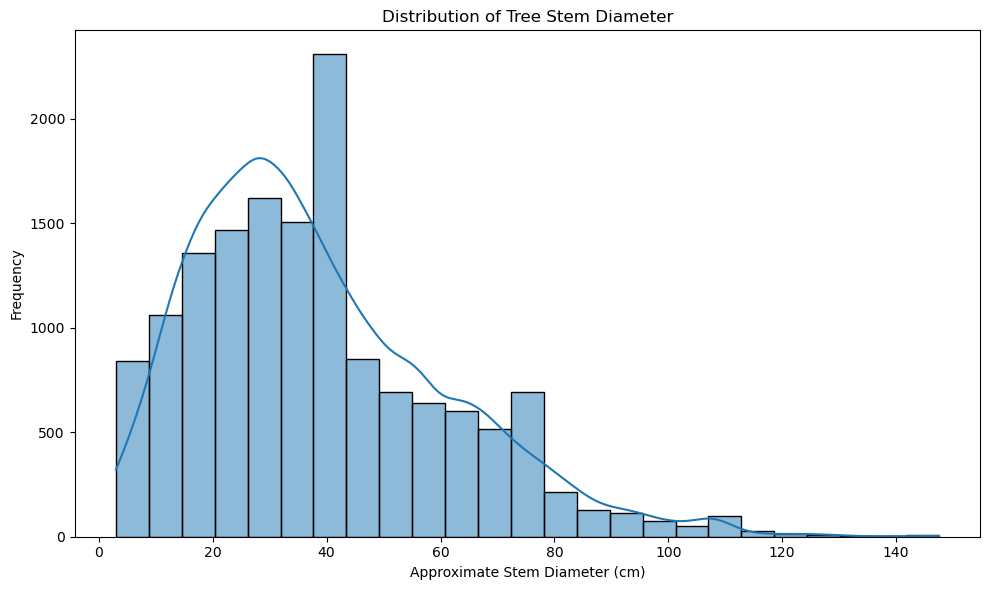

Mean: 38.6
Median: 33.0
Standard deviation: 22.27


In [51]:
#Graph 4:Distribution of Tree Stem Diameter"
diameter = df["StemDiameterMid"].dropna()
plt.figure(figsize=(10, 6))
sns.histplot(diameter, bins=25, kde=True)
plt.title("Distribution of Tree Stem Diameter")
plt.xlabel("Approximate Stem Diameter (cm)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
print("Mean:", round(diameter.mean(), 2))
print("Median:", round(diameter.median(), 2))
print("Standard deviation:", round(diameter.std(), 2))

In [22]:
conditions = df["Condition"].dropna()

In [23]:
success_label = "Good (Normal Vitality. No Major Defects)"

In [24]:
p = (conditions == success_label).mean()
print("Estimated probability of Good condition:", round(p, 4))
print("Estimated percentage:", round(p * 100, 2), "%")

Estimated probability of Good condition: 0.1124
Estimated percentage: 11.24 %


In [26]:
n = 20
k = np.arange(0, n + 1)

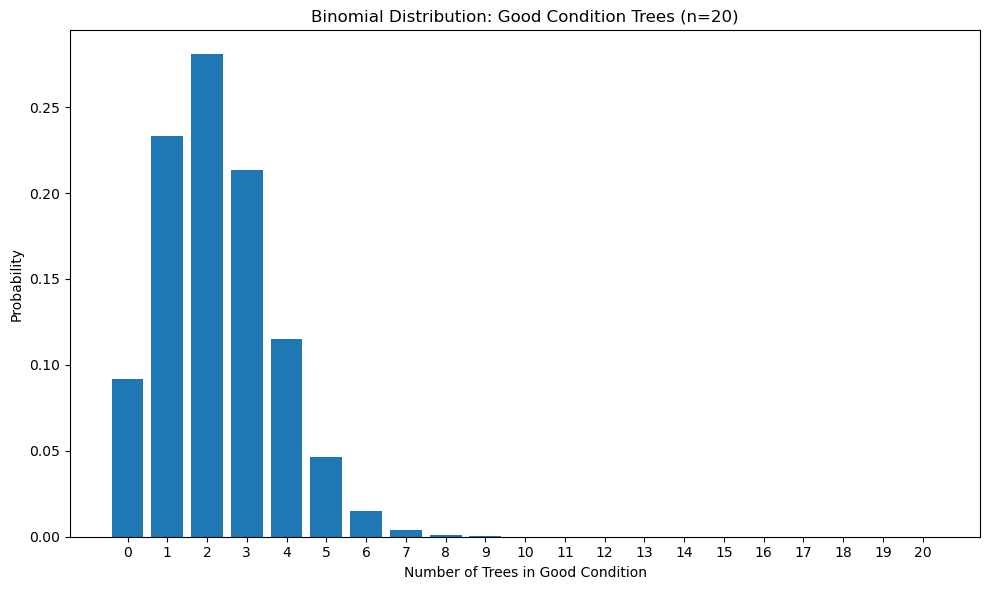

In [27]:
probabilities = binom.pmf(k, n, p)
plt.figure(figsize=(10, 6))
plt.bar(k, probabilities)
plt.title("Binomial Distribution: Good Condition Trees (n=20)")
plt.xlabel("Number of Trees in Good Condition")
plt.ylabel("Probability")
plt.xticks(k)
plt.tight_layout()
plt.show()

In [28]:
print("Expected number of successes:", round(n * p, 2))
print("Variance:", round(n * p * (1 - p), 2))
print("Standard deviation:", round(np.sqrt(n * p * (1 - p)), 2))

Expected number of successes: 2.25
Variance: 2.0
Standard deviation: 1.41


In [29]:
street_data = df["Street"].dropna().str.strip().str.upper()

In [32]:
trees_per_street = street_data.value_counts()

In [33]:
lambda_poisson = trees_per_street.mean()
print("Number of streets:", len(trees_per_street))
print("Mean trees per street (lambda):", round(lambda_poisson, 2))
print("Variance of street counts:", round(trees_per_street.var(), 2))

Number of streets: 559
Mean trees per street (lambda): 26.33
Variance of street counts: 7292.91


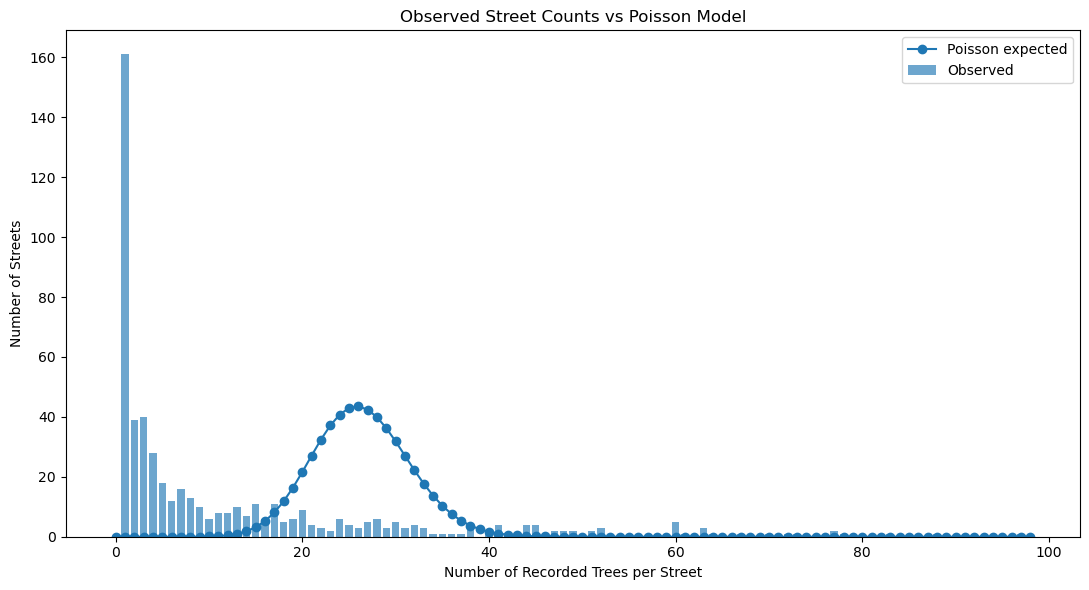

In [36]:
max_k = int(trees_per_street.quantile(0.95))
k = np.arange(0, max_k + 1)
observed = np.array([
    (trees_per_street == value).sum() for value in k
])
expected = len(trees_per_street) * poisson.pmf(
    k, lambda_poisson
)
plt.figure(figsize=(11, 6))
plt.bar(k, observed, alpha=0.65, label="Observed")
plt.plot(k, expected, "o-", label="Poisson expected")
plt.title("Observed Street Counts vs Poisson Model")
plt.xlabel("Number of Recorded Trees per Street")
plt.ylabel("Number of Streets")
plt.legend()
plt.tight_layout()
plt.show()

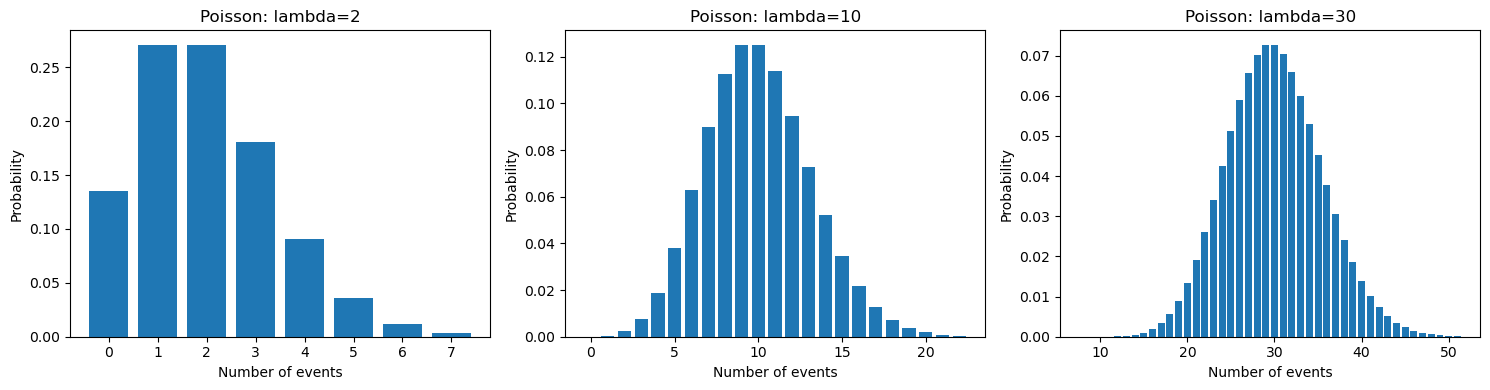

In [38]:
lambda_values = [2, 10, 30]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lam in zip(axes, lambda_values):
    k = np.arange(
        max(0, int(lam - 4 * np.sqrt(lam))),
        int(lam + 4 * np.sqrt(lam)) + 1
    )
    probabilities = poisson.pmf(k, lam)
    ax.bar(k, probabilities)
    ax.set_title(f"Poisson: lambda={lam}")
    ax.set_xlabel("Number of events")
    ax.set_ylabel("Probability")
plt.tight_layout()
plt.show()

In [53]:
print("Skewness:", round(stats.skew(diameter), 3))
print("Excess kurtosis:", round(stats.kurtosis(diameter), 3))

Skewness: 0.909
Excess kurtosis: 0.746


In [55]:
mu = diameter.mean()
sigma = diameter.std(ddof=1)
summary = pd.DataFrame({
    "Analysis": [
        "Binomial",
        "Poisson",
        "Normal"
    ],
    "Variable": [
        "Good condition (success/failure)",
        "Number of trees per street",
        "Approximate stem diameter"
    ],
    "Observations": [
        known_condition_count,
        len(trees_per_street),
        len(diameter)
    ],
    "Main Parameter": [
        f"p = {p:.4f}",
        f"lambda = {lambda_poisson:.2f}",
        f"mean = {mu:.2f}, SD = {sigma:.2f}"
    ]
})
display(summary)

,Analysis,Variable,Observations,Main Parameter
0,Binomial,Good condition (success/failure),15015,p = 0.1124
1,Poisson,Number of trees per street,559,lambda = 26.33
2,Normal,Approximate stem diameter,14903,"mean = 38.60, SD = 22.27"
